# 02 · Exploratory Data Analysis

**Netflix Customer Intelligence, Churn Prediction & AI Analytics Copilot** · Week 1, Days 6–7

This notebook reads the cleaned data straight from the MySQL database (`netflix_ci`) built on Days 3–4 and produces **33 charts**
(PRD Section 10 asks for at least 20). Every chart is saved to `reports/figures/`.

| Section | Charts | Question |
|---|---|---|
| 1. Customers | 1–5 | Who are our customers? |
| 2. Plans & revenue | 6–8 | Where does the money come from? |
| 3. Cancellations | 9–11 | When and why do customers leave? |
| 4. Engagement | 12–16 | How do people watch? |
| 5. Churn drivers | 17–24 | Which groups churn the most? |
| 6. Support | 25–27 | How is support performing? |
| 7. Complaints vs. satisfaction | 28–31 | What are people unhappy about? |
| 8. Putting it together | 32–33 | Which signals move together? |

**Reading note.** The data is a fixed snapshot: viewing and support activity end on **2026-06-30** and payments end on 2026-05-31,
so "now" means the end of the data, never today's date. Churn events only occur between 2025-10 and 2026-06.

In [1]:
import sys
print(sys.executable)

<project folder>\.venv\Scripts\python.exe


In [2]:
from pathlib import Path
print(Path.cwd())

<project folder>\notebooks


In [3]:
# ── 0. Setup ──────────────────────────────────────────────────────────────────
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Find the project root (the folder that contains src/utils/config.py)
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "src" / "utils" / "config.py").exists()), None)
assert ROOT is not None, "Keep this notebook inside the project folder (notebooks/)."
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sqlalchemy import text
from src.database.connection import get_engine

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

NETFLIX_RED, DARK, GREY, BLUE = "#E50914", "#221F1F", "#8C8C8C", "#3B6EA8"
PLAN_ORDER  = ["Basic", "Standard", "Premium"]
PLAN_COLORS = {"Basic": "#B3B3B3", "Standard": BLUE, "Premium": NETFLIX_RED}

sns.set_theme(style="whitegrid", context="notebook",
              rc={"axes.spines.top": False, "axes.spines.right": False})
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold", "axes.titlesize": 13})


def finish(num, name, fig=None):
    """Tidy the figure, save it to reports/figures and show it."""
    fig = fig or plt.gcf()
    fig.tight_layout()
    path = FIG_DIR / f"eda_{num:02d}_{name}.png"
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    print(f"Saved chart {num}: {path.relative_to(ROOT)}")

print("Project root:", ROOT)

Project root: <project folder>


In [4]:
# ── 1. Load all 9 tables from MySQL ──────────────────────────────────────────
engine = get_engine()
TABLES = ["customers", "subscription_plans", "subscriptions", "content", "viewing_activity",
          "payments", "support_tickets", "customer_feedback", "churn_labels"]

with engine.connect() as conn:
    raw = {t: pd.read_sql(text(f"SELECT * FROM `{t}`"), conn) for t in TABLES}

for t, df in raw.items():
    print(f"{t:20s} {df.shape[0]:>8,} rows x {df.shape[1]:>2} cols")

customers               8,000 rows x 13 cols
subscription_plans          3 rows x  6 cols
subscriptions           8,875 rows x 13 cols
content                   500 rows x  9 cols
viewing_activity       66,422 rows x 13 cols
payments              110,735 rows x 11 cols
support_tickets         6,120 rows x 12 cols
customer_feedback       5,046 rows x  8 cols
churn_labels            8,000 rows x  4 cols


In [5]:
# ── 2. Fix types (MySQL returns DATE as date objects and BOOLEAN as 0/1) ───────
DATE_COLS = {
    "customers": ["registration_date"],
    "subscriptions": ["subscription_start_date", "subscription_end_date", "cancellation_date", "effective_end_date"],
    "viewing_activity": ["viewing_date"], "payments": ["payment_date"],
    "support_tickets": ["ticket_date"], "customer_feedback": ["feedback_date"], "churn_labels": ["churn_date"],
}
BOOL_COLS = {
    "customers": ["country_imputed", "age_imputed"],
    "subscriptions": ["auto_renew", "is_current", "cancel_before_start"],
    "viewing_activity": ["completion_imputed", "watch_outlier", "session_adjusted"],
    "payments": ["amount_anomaly", "in_subscription_window"],
    "support_tickets": ["ticket_date_invalid"], "customer_feedback": ["sentiment_mismatch"],
    "churn_labels": ["churned"],
}
NUM_COLS = {
    "payments": ["amount", "amount_clean"],
    "viewing_activity": ["watch_duration_minutes", "completion_percentage", "session_duration_minutes", "watch_duration_raw"],
    "support_tickets": ["resolution_time_hours", "customer_satisfaction_score"],
    "customer_feedback": ["rating"], "subscription_plans": ["monthly_price"], "customers": ["age"],
}
for t, cols in DATE_COLS.items():
    for c in cols: raw[t][c] = pd.to_datetime(raw[t][c])
for t, cols in BOOL_COLS.items():
    for c in cols: raw[t][c] = raw[t][c].astype(bool)
for t, cols in NUM_COLS.items():
    for c in cols: raw[t][c] = pd.to_numeric(raw[t][c])

customers, plans, subs, content, viewing, payments, tickets, feedback, churn = (raw[t] for t in TABLES)

AS_OF     = viewing["viewing_date"].max()      # end of the data
FIRST_DAY = viewing["viewing_date"].min()      # start of the viewing data
print("Viewing data:", FIRST_DAY.date(), "->", AS_OF.date())

Viewing data: 2025-07-01 -> 2026-06-30


In [6]:
# ── 3. One row per customer (used by the churn charts) ───────────────────────
# NOTE: engagement here describes activity going INTO a cancellation, which is what makes it a useful
# warning sign. For modelling (Week 2) features must be cut off before the prediction date to avoid leakage.
# Current plan = the subscription row that is not 'Plan Changed' (every customer has exactly one)
cur = (subs[subs.subscription_status != "Plan Changed"]
       .merge(plans[["plan_id", "plan_name"]], on="plan_id")
       [["customer_id", "plan_name", "auto_renew", "subscription_status"]])

watch = viewing.groupby("customer_id").agg(total_watch=("watch_duration_minutes", "sum"),
                                           sessions=("viewing_id", "count"))
pay   = payments.groupby("customer_id").agg(payments=("payment_id", "count"),
                                            failed=("payment_status", lambda s: (s == "Failed").sum()))
tix   = tickets.groupby("customer_id").agg(tickets=("ticket_id", "count"),
                                           avg_csat=("customer_satisfaction_score", "mean"))

cust = (customers.merge(churn, on="customer_id").merge(cur, on="customer_id")
        .merge(watch, on="customer_id", how="left").merge(pay, on="customer_id", how="left")
        .merge(tix, on="customer_id", how="left"))
for c in ["total_watch", "sessions", "payments", "failed", "tickets"]:
    cust[c] = cust[c].fillna(0)

# tenure at the end of the data
cust["tenure_days"]   = (AS_OF - cust.registration_date).dt.days
cust["failed_rate"]   = cust.failed / cust.payments.replace(0, np.nan)

# Recent activity = minutes watched in the 90 days up to the customer's observation end
# (the cancellation date for churned customers, the end of the data for everyone else).
obs_end = cust.set_index("customer_id").churn_date.fillna(AS_OF).clip(upper=AS_OF).rename("obs_end")
v_end   = viewing.merge(obs_end.reset_index(), on="customer_id")
in_win  = (v_end.viewing_date <= v_end.obs_end) & (v_end.viewing_date > v_end.obs_end - pd.Timedelta(days=90))
recent  = v_end[in_win].groupby("customer_id").watch_duration_minutes.sum().rename("recent_watch_90d")
cust = cust.merge(recent, on="customer_id", how="left")
cust["recent_watch_90d"] = cust.recent_watch_90d.fillna(0)

# buckets
cust["tenure_bucket"] = pd.cut(cust.tenure_days, [-1, 90, 180, 365, 730, 1095, np.inf],
                               labels=["< 3 mo", "3-6 mo", "6-12 mo", "1-2 yrs", "2-3 yrs", "3+ yrs"])
cust["engagement_tier"] = pd.qcut(cust.recent_watch_90d.rank(method="first"), 4,
                                  labels=["Low", "Medium", "High", "Very high"])
cust["failed_bucket"] = cust.failed.clip(upper=3).astype(int).astype(str).replace({"3": "3+"})
cust["ticket_bucket"] = cust.tickets.clip(upper=4).astype(int).astype(str).replace({"4": "4+"})
cust["auto_renew_label"] = np.where(cust.auto_renew, "Auto-renew ON", "Auto-renew OFF")

OVERALL = cust.churned.mean()
print(f"{len(cust):,} customers | overall churn rate {OVERALL:.2%} | {cust.churned.sum():,} churned")
cust[["customer_id", "country", "plan_name", "tenure_days", "recent_watch_90d", "failed", "tickets", "churned"]].head()

8,000 customers | overall churn rate 24.89% | 1,991 churned


,customer_id,country,plan_name,tenure_days,recent_watch_90d,failed,tickets,churned
0,CUST000001,United States,Premium,1522,120.0,0,2.0,False
1,CUST000002,France,Standard,188,116.0,0,1.0,False
2,CUST000003,Germany,Premium,2389,3.0,0,1.0,True
3,CUST000004,Australia,Basic,2710,218.0,1,0.0,False
4,CUST000005,United States,Basic,706,102.0,1,0.0,False


In [7]:
# ── Helper: churn rate by a grouping column ─────────────────────────────────
def churn_rate_chart(col, num, name, title, order=None, xlabel=None, horizontal=False, figsize=(8, 4.5)):
    g = cust.groupby(col, observed=True).churned.agg(rate="mean", n="size")
    g = g.reindex(order) if order is not None else g.sort_values("rate", ascending=False)
    fig, ax = plt.subplots(figsize=figsize)
    label = f"Overall {OVERALL:.1%}"
    if horizontal:
        g = g.iloc[::-1]
        ax.barh(g.index.astype(str), g.rate * 100, color=NETFLIX_RED)
        ax.axvline(OVERALL * 100, color=DARK, ls="--", lw=1.2, label=label)
        for y, (r, n) in enumerate(zip(g.rate, g.n)):
            ax.text(r * 100 - 0.3, y, f"{r:.1%}  (n={n:,})", va="center", ha="right", fontsize=8, color="white", fontweight="bold")
        ax.set_xlabel("Churn rate (%)"); ax.set_xlim(0, g.rate.max() * 100 * 1.3)
    else:
        ax.bar(g.index.astype(str), g.rate * 100, color=NETFLIX_RED)
        ax.axhline(OVERALL * 100, color=DARK, ls="--", lw=1.2, label=label)
        for x, (r, n) in enumerate(zip(g.rate, g.n)):
            ax.text(x, r * 100 / 2, f"{r:.1%}\n(n={n:,})", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
        ax.set_ylabel("Churn rate (%)"); ax.set_ylim(0, g.rate.max() * 100 * 1.3); ax.set_xlabel(xlabel or col)
    ax.set_title(title); ax.legend(loc="lower right" if horizontal else "upper left")
    finish(num, name, fig)
    return g

## 1 · Customers

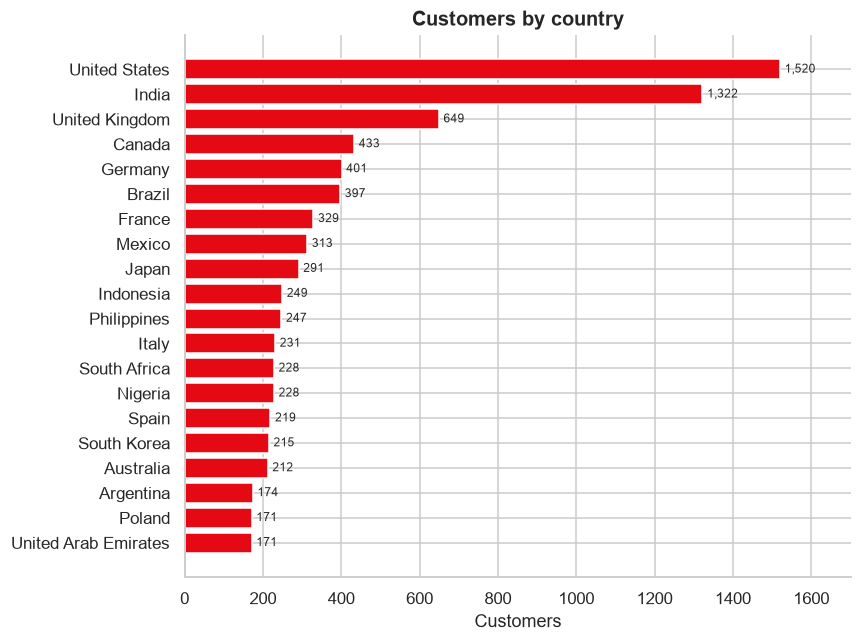

Saved chart 1: reports\figures\eda_01_customers_by_country.png


In [8]:
# Chart 1 — Customers by country
vc = cust.country.value_counts()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(vc.index[::-1], vc.values[::-1], color=NETFLIX_RED)
for y, v in enumerate(vc.values[::-1]):
    ax.text(v + 12, y, f"{v:,}", va="center", fontsize=8)
ax.set_title("Customers by country"); ax.set_xlabel("Customers"); ax.set_xlim(0, vc.max() * 1.12)
finish(1, "customers_by_country", fig)

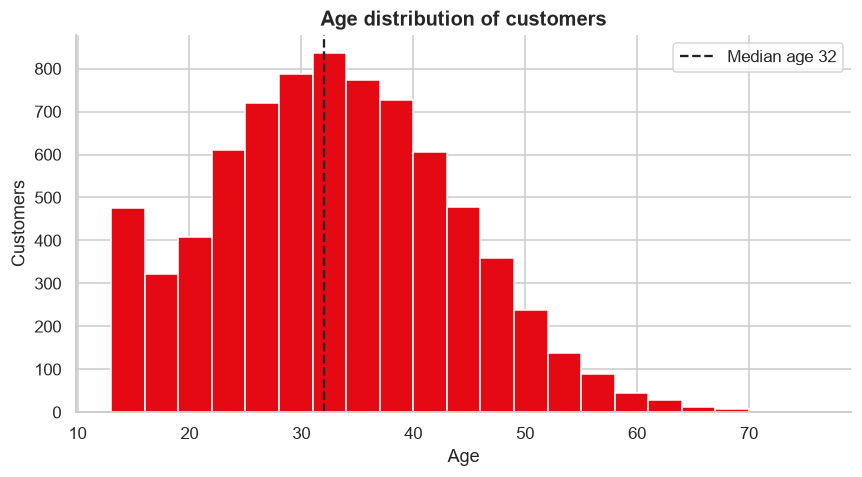

Saved chart 2: reports\figures\eda_02_age_distribution.png


In [9]:
# Chart 2 — Age distribution (customers whose age was imputed are excluded)
ages = cust.loc[~cust.age_imputed, "age"].astype(float)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(ages, bins=range(int(ages.min()), int(ages.max()) + 3, 3), color=NETFLIX_RED, edgecolor="white")
ax.axvline(ages.median(), color=DARK, ls="--", label=f"Median age {ages.median():.0f}")
ax.set_title("Age distribution of customers"); ax.set_xlabel("Age"); ax.set_ylabel("Customers"); ax.legend()
finish(2, "age_distribution", fig)

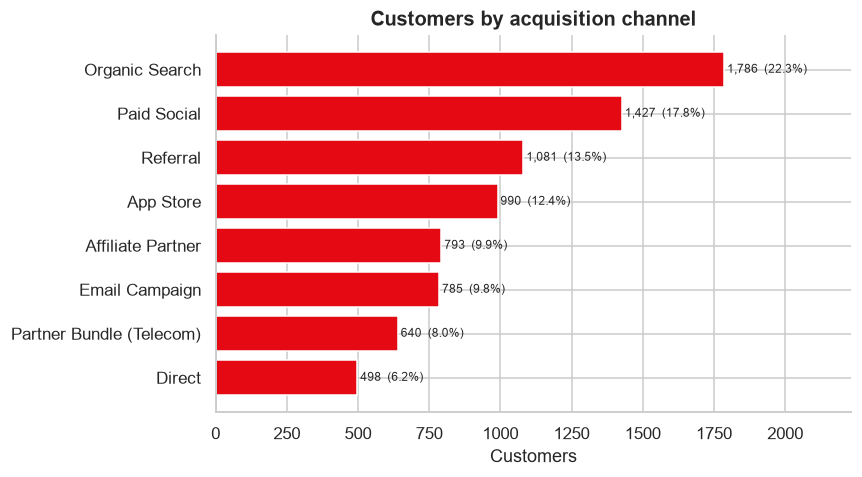

Saved chart 3: reports\figures\eda_03_customers_by_channel.png


In [10]:
# Chart 3 — Customers by acquisition channel
vc = cust.acquisition_channel.value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(vc.index[::-1], vc.values[::-1], color=NETFLIX_RED)
for y, v in enumerate(vc.values[::-1]):
    ax.text(v + 10, y, f"{v:,}  ({v / len(cust):.1%})", va="center", fontsize=8)
ax.set_title("Customers by acquisition channel"); ax.set_xlabel("Customers"); ax.set_xlim(0, vc.max() * 1.25)
finish(3, "customers_by_channel", fig)

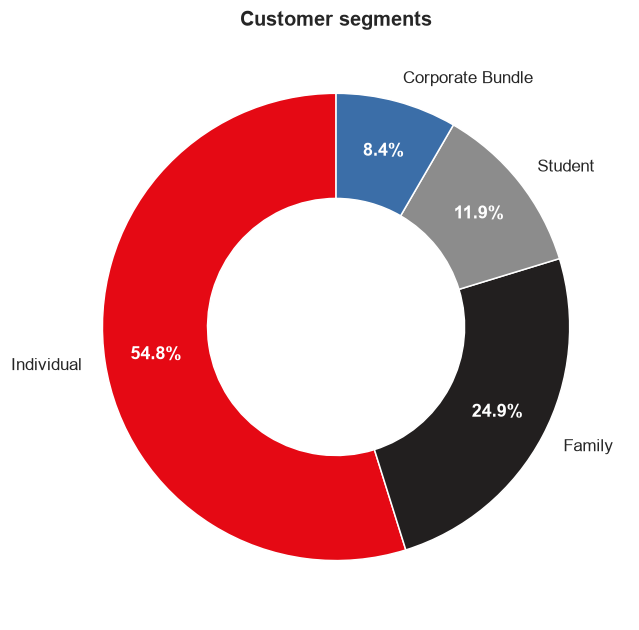

Saved chart 4: reports\figures\eda_04_customer_segments.png


In [11]:
# Chart 4 — Customer segment mix
seg = cust.customer_segment.value_counts()
fig, ax = plt.subplots(figsize=(6, 6))
wedges, labels_, pcts = ax.pie(seg.values, labels=seg.index, autopct="%1.1f%%", startangle=90, pctdistance=0.78,
                               colors=[NETFLIX_RED, DARK, GREY, BLUE][:len(seg)], wedgeprops=dict(width=0.45, edgecolor="white"))
for t in pcts: t.set_color("white"); t.set_fontweight("bold")
ax.set_title("Customer segments")
finish(4, "customer_segments", fig)

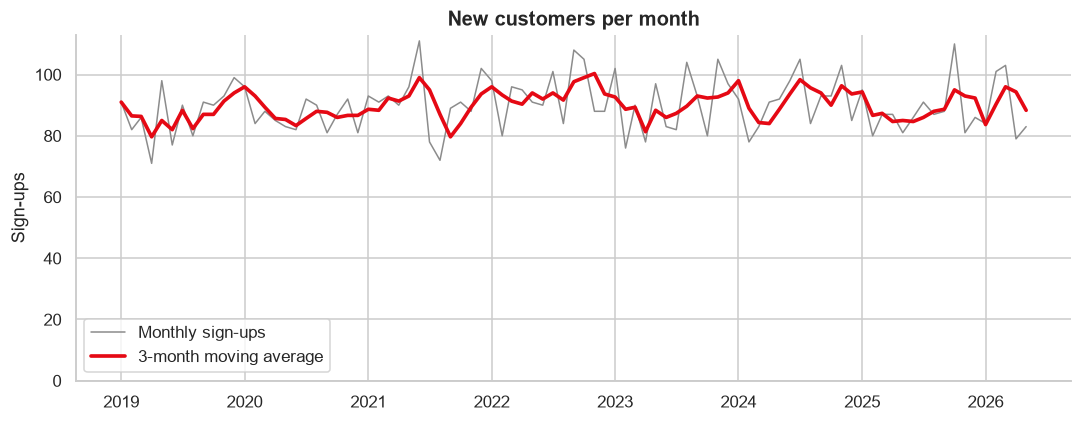

Saved chart 5: reports\figures\eda_05_signups_per_month.png


In [12]:
# Chart 5 — New sign-ups per month
signups = cust.set_index("registration_date").resample("MS").size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(signups.index, signups.values, color=GREY, lw=1, label="Monthly sign-ups")
ax.plot(signups.index, signups.rolling(3, min_periods=1).mean(), color=NETFLIX_RED, lw=2.4, label="3-month moving average")
ax.set_title("New customers per month"); ax.set_ylabel("Sign-ups"); ax.set_ylim(0); ax.legend()
finish(5, "signups_per_month", fig)

**What the charts show**
- Three countries hold 43.6% of customers: United States (19.0%), India (16.5%) and United Kingdom (8.1%). 20 countries in total.
- The median age is 32, and about 40% of customers are under 30.
- Individuals are 55% of customers, Family 25%, Student 12% and Corporate Bundle 8%.
- Organic Search (22%) and Paid Social (18%) bring in the most customers.
- Sign-ups are steady at about 90 a month (range 71–111), so growth is not driven by a surge.

## 2 · Plans & revenue

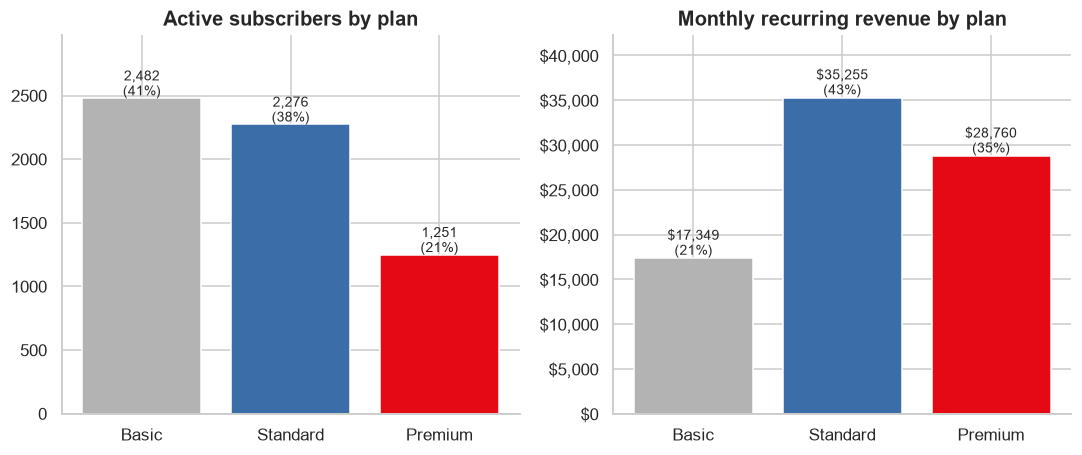

Saved chart 6: reports\figures\eda_06_plans_subscribers_and_mrr.png


In [13]:
# Chart 6 — Active subscribers and monthly recurring revenue (MRR) by plan
active = cust[cust.subscription_status == "Active"]
price  = plans.set_index("plan_name").monthly_price.reindex(PLAN_ORDER)
n_subs = active.plan_name.value_counts().reindex(PLAN_ORDER)
mrr    = n_subs * price
colors = [PLAN_COLORS[p] for p in PLAN_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
axes[0].bar(PLAN_ORDER, n_subs, color=colors)
for x, v in enumerate(n_subs):
    axes[0].text(x, v + 20, f"{v:,}\n({v / n_subs.sum():.0%})", ha="center", fontsize=9)
axes[0].set_title("Active subscribers by plan"); axes[0].set_ylim(0, n_subs.max() * 1.2)

axes[1].bar(PLAN_ORDER, mrr, color=colors)
for x, v in enumerate(mrr):
    axes[1].text(x, v + 400, f"${v:,.0f}\n({v / mrr.sum():.0%})", ha="center", fontsize=9)
axes[1].set_title("Monthly recurring revenue by plan"); axes[1].set_ylim(0, mrr.max() * 1.2)
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
finish(6, "plans_subscribers_and_mrr", fig)

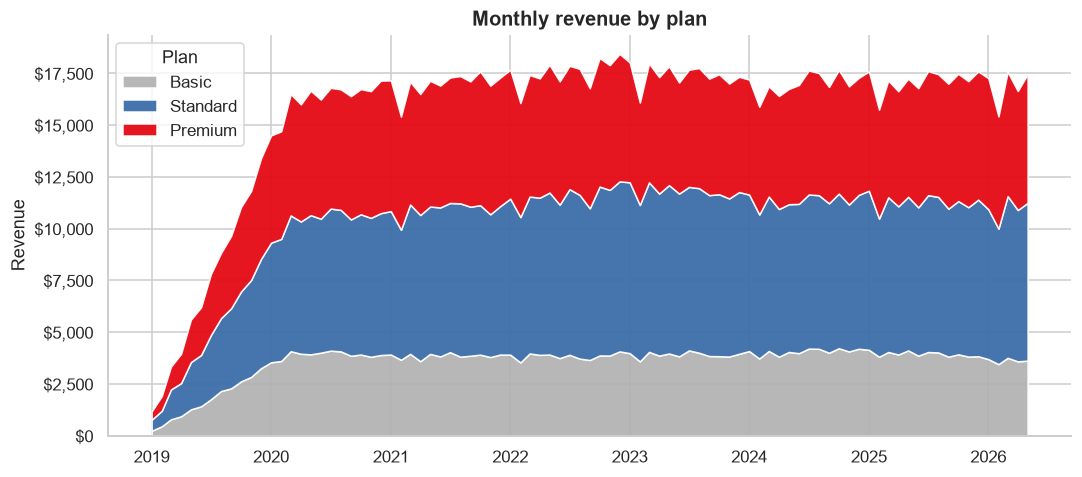

Saved chart 7: reports\figures\eda_07_monthly_revenue_by_plan.png


In [14]:
# Chart 7 — Monthly revenue by plan (successful payments)
rev = (payments[payments.payment_status == "Success"]
       .merge(subs[["subscription_id", "plan_id"]], on="subscription_id")
       .merge(plans[["plan_id", "plan_name"]], on="plan_id"))
monthly_rev = (rev.assign(month=rev.payment_date.dt.to_period("M").dt.to_timestamp())
                  .pivot_table(index="month", columns="plan_name", values="amount_clean", aggfunc="sum")
                  .fillna(0)[PLAN_ORDER])
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.stackplot(monthly_rev.index, [monthly_rev[p] for p in PLAN_ORDER], labels=PLAN_ORDER,
             colors=[PLAN_COLORS[p] for p in PLAN_ORDER], alpha=0.95)
ax.set_title("Monthly revenue by plan"); ax.set_ylabel("Revenue"); ax.legend(loc="upper left", title="Plan")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
finish(7, "monthly_revenue_by_plan", fig)

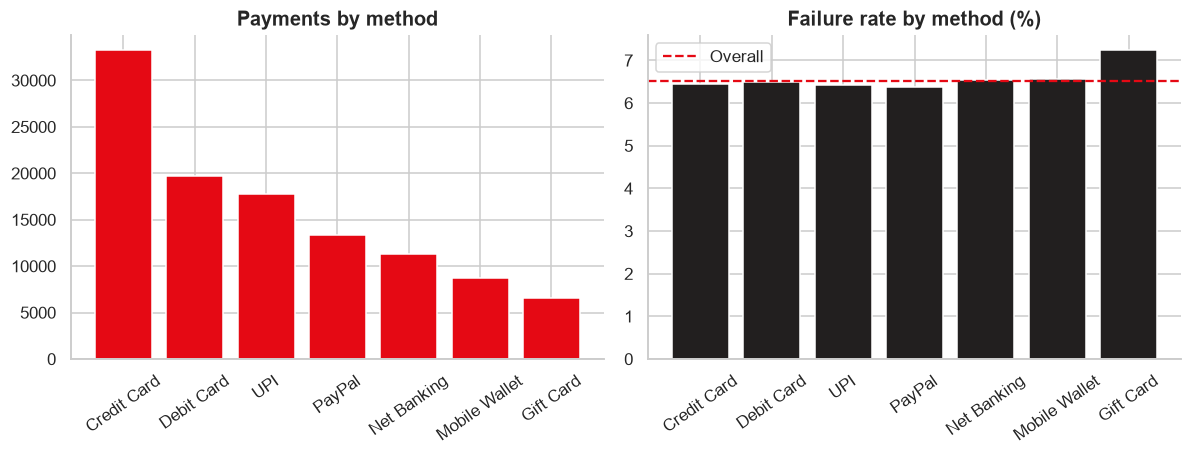

Saved chart 8: reports\figures\eda_08_payment_methods.png


In [15]:
# Chart 8 — Payment methods: volume and failure rate
pm = (payments.groupby("payment_method")
      .agg(n=("payment_id", "size"), fail_rate=("payment_status", lambda s: (s == "Failed").mean()))
      .sort_values("n", ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].bar(pm.index, pm.n, color=NETFLIX_RED)
axes[0].set_title("Payments by method"); axes[0].tick_params(axis="x", rotation=35)
axes[1].bar(pm.index, pm.fail_rate * 100, color=DARK)
axes[1].axhline((payments.payment_status == "Failed").mean() * 100, color=NETFLIX_RED, ls="--", label="Overall")
axes[1].set_title("Failure rate by method (%)"); axes[1].tick_params(axis="x", rotation=35); axes[1].legend()
finish(8, "payment_methods", fig)

**What the charts show**
- Basic has the most active subscribers (2,482, 41%), but Standard earns the most: $35,255 a month, 43% of the $81,365 total MRR.
- Premium is only 21% of subscribers but 35% of MRR ($28,760).
- Revenue climbed quickly through 2019–2020, then levelled off at roughly $17,000–18,000 a month.
- Payments fail about 6.5% of the time on every method (Gift Card is slightly higher at 7.2%), so payment method is not a driver of failures.

## 3 · Cancellations

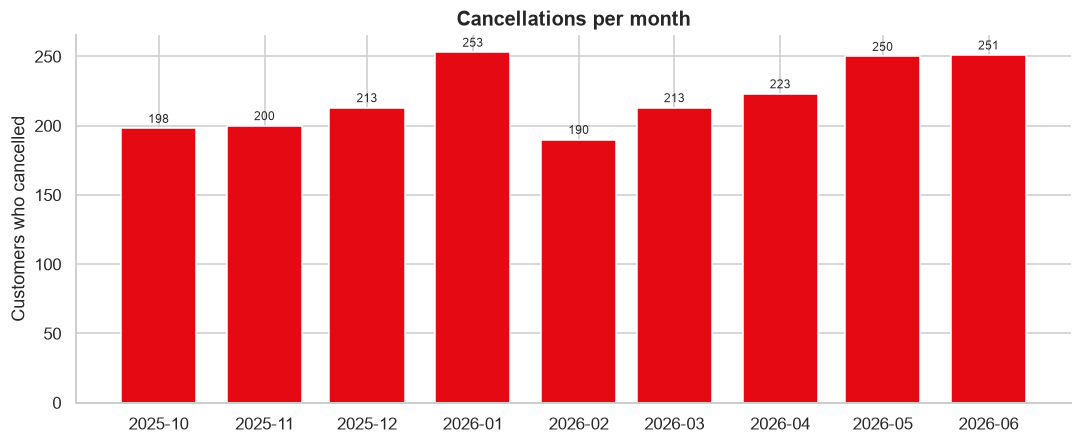

Saved chart 9: reports\figures\eda_09_cancellations_per_month.png


In [16]:
# Chart 9 — Cancellations per month
canc = cust[cust.churned].copy()
per_month = canc.set_index("churn_date").resample("MS").size()
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(per_month.index, per_month.values, width=22, color=NETFLIX_RED)
for x, v in zip(per_month.index, per_month.values):
    ax.text(x, v + 4, str(v), ha="center", fontsize=8)
ax.set_title("Cancellations per month"); ax.set_ylabel("Customers who cancelled")
finish(9, "cancellations_per_month", fig)

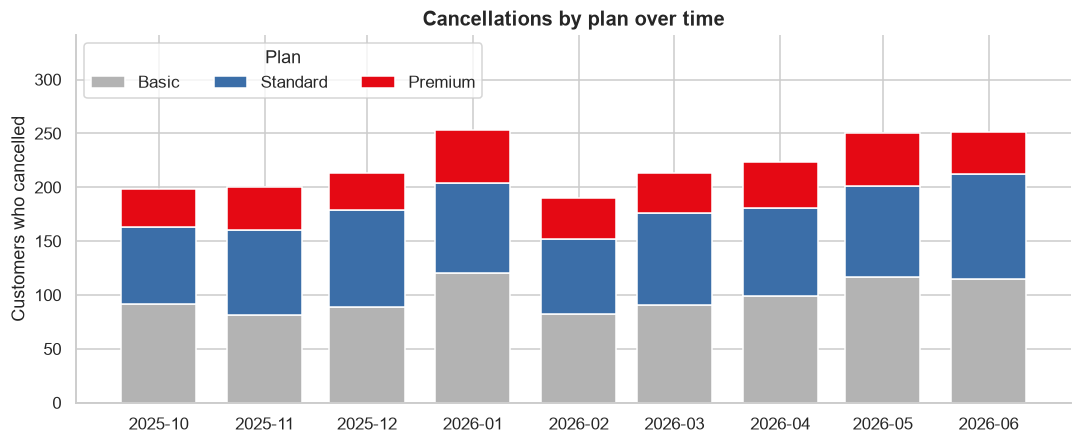

Saved chart 10: reports\figures\eda_10_cancellations_by_plan.png


In [17]:
# Chart 10 — Cancellations per month, split by plan
canc["month"] = canc.churn_date.dt.to_period("M").dt.to_timestamp()
cm = canc.pivot_table(index="month", columns="plan_name", values="customer_id", aggfunc="count").fillna(0)
cm = cm.reindex(columns=PLAN_ORDER, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.2))
bottom = np.zeros(len(cm))
for p in PLAN_ORDER:
    ax.bar(cm.index, cm[p], bottom=bottom, width=22, label=p, color=PLAN_COLORS[p])
    bottom = bottom + cm[p].values
ax.set_title("Cancellations by plan over time"); ax.set_ylabel("Customers who cancelled")
ax.set_ylim(0, cm.sum(axis=1).max() * 1.35); ax.legend(title="Plan", ncol=3, loc="upper left")
finish(10, "cancellations_by_plan", fig)

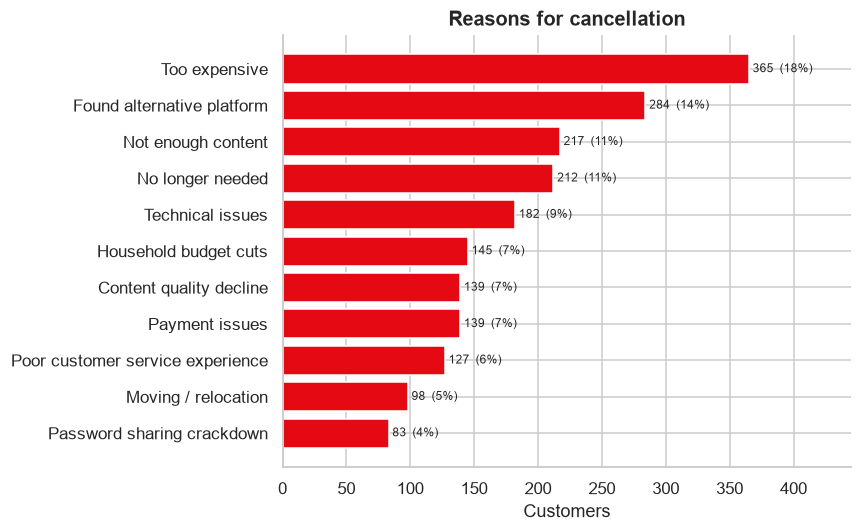

Saved chart 11: reports\figures\eda_11_churn_reasons.png


In [18]:
# Chart 11 — Why customers cancel
reasons = canc.churn_reason.value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(reasons.index[::-1], reasons.values[::-1], color=NETFLIX_RED)
for y, v in enumerate(reasons.values[::-1]):
    ax.text(v + 3, y, f"{v:,}  ({v / reasons.sum():.0%})", va="center", fontsize=8)
ax.set_title("Reasons for cancellation"); ax.set_xlabel("Customers"); ax.set_xlim(0, reasons.max() * 1.22)
finish(11, "churn_reasons", fig)

**What the charts show**
- 1,991 customers cancelled between October 2025 and June 2026. Monthly cancellations rose from 198 in October to about 250 in January, May and June.
- Basic accounts for 44.5% of cancellations against 42.1% of customers; Premium for 18.2% against 20.2%.
- The top reasons are Too expensive (18.3%), Found alternative platform (14.3%) and Not enough content (10.9%). Price-related reasons together (Too expensive plus Household budget cuts) make up 25.6%.

## 4 · Engagement

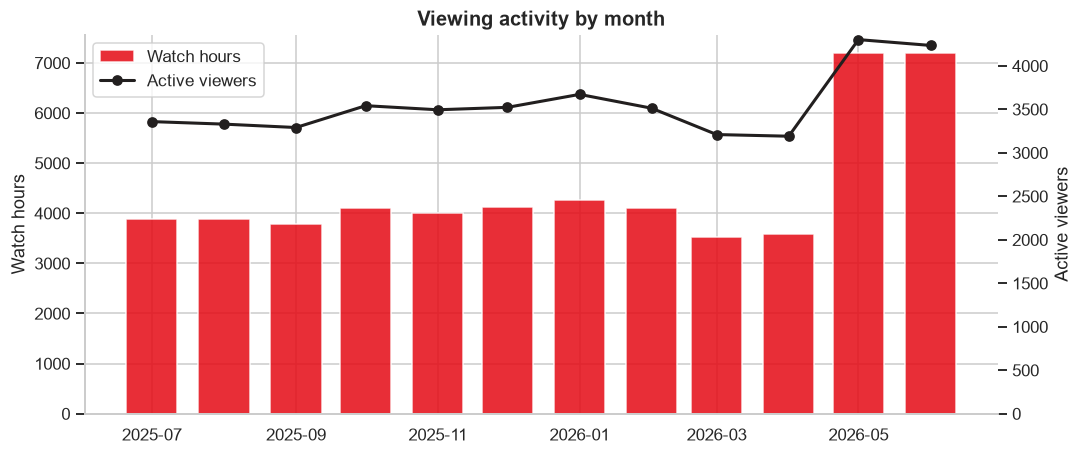

Saved chart 12: reports\figures\eda_12_monthly_watch_hours_and_viewers.png


In [19]:
# Chart 12 — Watch hours and active viewers per month
month_key = viewing.viewing_date.dt.to_period("M").dt.to_timestamp()
vm = viewing.groupby(month_key).agg(hours=("watch_duration_minutes", lambda s: s.sum() / 60),
                                    viewers=("customer_id", "nunique"))
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.bar(vm.index, vm.hours, width=22, color=NETFLIX_RED, alpha=0.85, label="Watch hours")
ax.set_ylabel("Watch hours"); ax.set_title("Viewing activity by month")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(vm.index, vm.viewers, color=DARK, marker="o", lw=2, label="Active viewers")
ax2.set_ylabel("Active viewers"); ax2.set_ylim(0)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
finish(12, "monthly_watch_hours_and_viewers", fig)

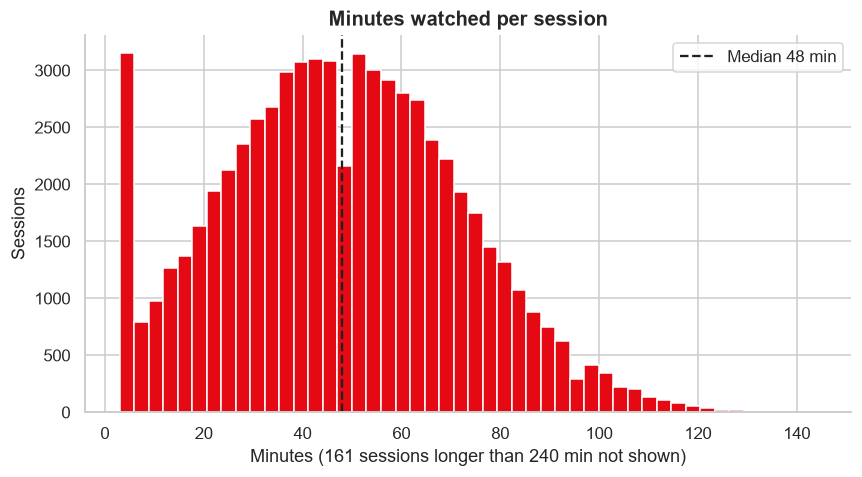

Saved chart 13: reports\figures\eda_13_session_length.png


In [20]:
# Chart 13 — Length of a viewing session (minutes watched; sessions are capped at 300 min)
w = viewing.watch_duration_minutes
long_n = int((w > 240).sum())
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(w[w <= 240], bins=48, color=NETFLIX_RED, edgecolor="white")
ax.axvline(w.median(), color=DARK, ls="--", label=f"Median {w.median():.0f} min")
ax.set_title("Minutes watched per session"); ax.set_xlabel(f"Minutes ({long_n} sessions longer than 240 min not shown)")
ax.set_ylabel("Sessions"); ax.legend()
finish(13, "session_length", fig)

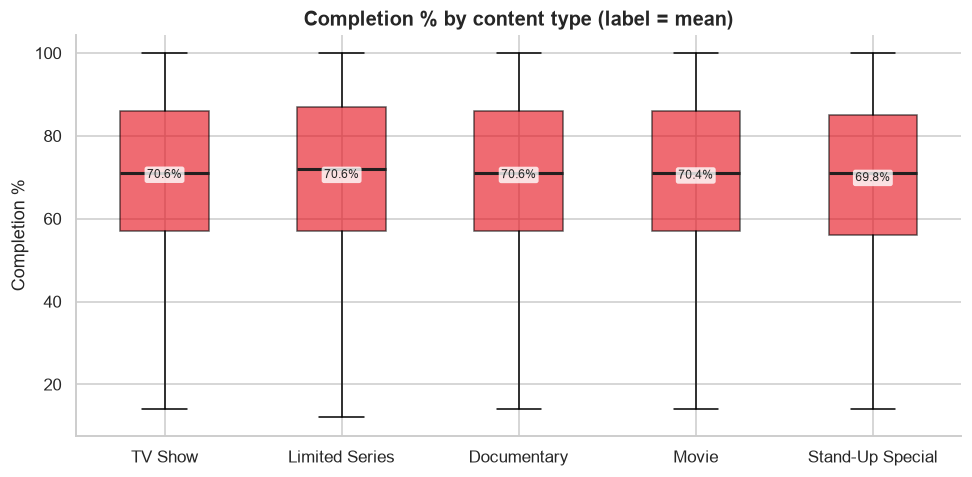

Saved chart 14: reports\figures\eda_14_completion_by_content_type.png


In [21]:
# Chart 14 — Completion % by content type
vc_ = viewing.merge(content[["content_id", "content_type", "genre"]], on="content_id")
order_t = vc_.groupby("content_type").completion_percentage.mean().sort_values(ascending=False).index.tolist()
data = [vc_.loc[vc_.content_type == t, "completion_percentage"] for t in order_t]
fig, ax = plt.subplots(figsize=(9, 4.5))
bp = ax.boxplot(data, showfliers=False, patch_artist=True,
                boxprops=dict(facecolor=NETFLIX_RED, alpha=0.6), medianprops=dict(color=DARK, lw=2))
ax.set_xticks(range(1, len(order_t) + 1)); ax.set_xticklabels(order_t)
for i, d in enumerate(data, 1):
    ax.text(i, d.mean(), f"{d.mean():.1f}%", ha="center", va="center", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
ax.set_title("Completion % by content type (label = mean)"); ax.set_ylabel("Completion %")
finish(14, "completion_by_content_type", fig)

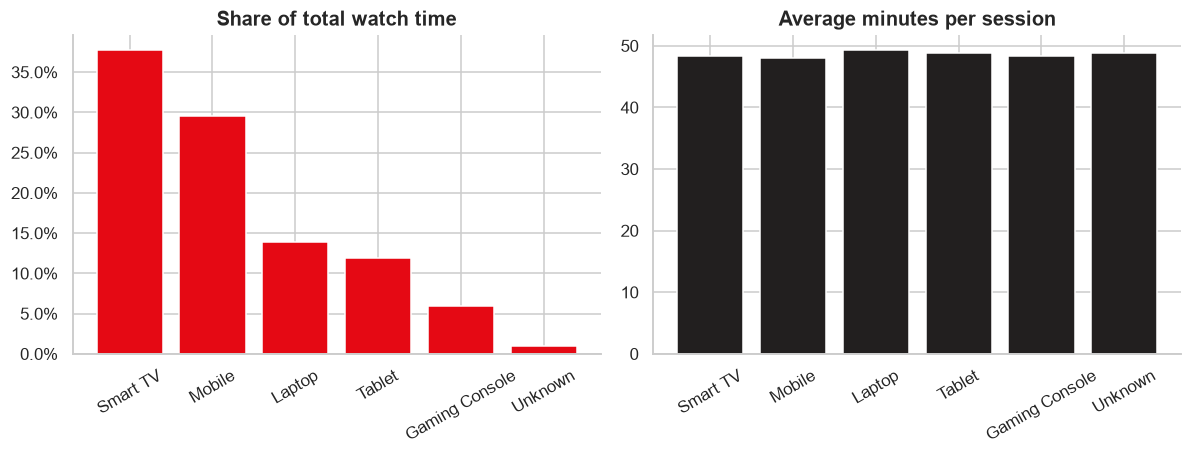

Saved chart 15: reports\figures\eda_15_device_usage.png


In [22]:
# Chart 15 — Devices: share of watch time and average session length
dev = (viewing.groupby("device_type")
       .agg(minutes=("watch_duration_minutes", "sum"), avg_session=("watch_duration_minutes", "mean"))
       .sort_values("minutes", ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].bar(dev.index, dev.minutes / dev.minutes.sum() * 100, color=NETFLIX_RED)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[0].tick_params(axis="x", rotation=30)
axes[0].set_title("Share of total watch time")
axes[1].bar(dev.index, dev.avg_session, color=DARK)
axes[1].tick_params(axis="x", rotation=30); axes[1].set_title("Average minutes per session")
finish(15, "device_usage", fig)

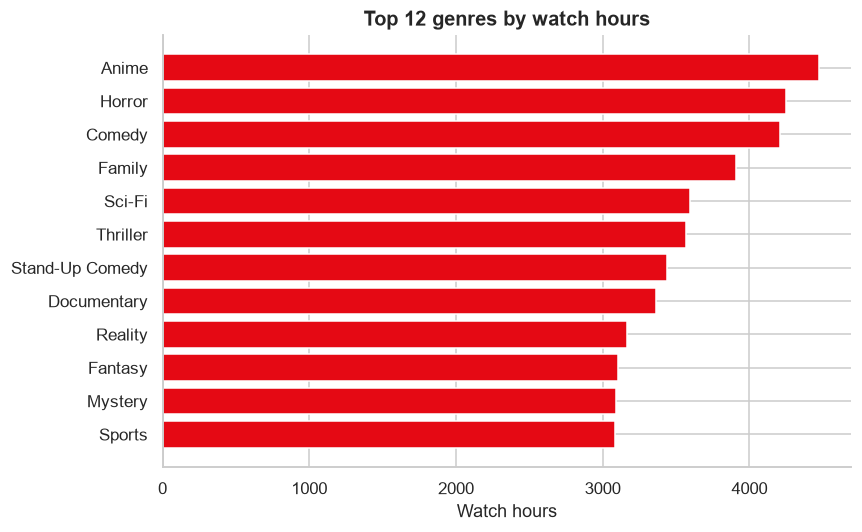

Saved chart 16: reports\figures\eda_16_top_genres.png


In [23]:
# Chart 16 — Top genres by watch hours
genre_hours = (vc_.groupby("genre").watch_duration_minutes.sum() / 60).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(genre_hours.index[::-1], genre_hours.values[::-1], color=NETFLIX_RED)
ax.set_title("Top 12 genres by watch hours"); ax.set_xlabel("Watch hours")
finish(16, "top_genres", fig)

**What the charts show**
- Viewing was steady at 3,500–4,300 watch hours and 3,200–3,700 active viewers a month until April 2026, then jumps to about 7,200 hours and 4,300 viewers in May and June. That jump looks like an artifact of how the data was generated, so treat the last two months with caution.
- The median session is 48 minutes. Only 2.1% of sessions reach 100 minutes or more.
- Completion is about 70% for every content type (69.8%–70.6%): content type does not change how much people finish.
- Smart TV (37.8%) and Mobile (29.6%) take two-thirds of watch time, and sessions last about 48 minutes on every device.
- Anime (4,471 hours), Horror (4,250) and Comedy (4,211) are the most-watched genres; Drama is the least (2,343).

## 5 · Churn drivers

_Each chart shows the share of customers in a group who cancelled. The dashed line is the overall churn rate. Bar labels show the group size (n)._

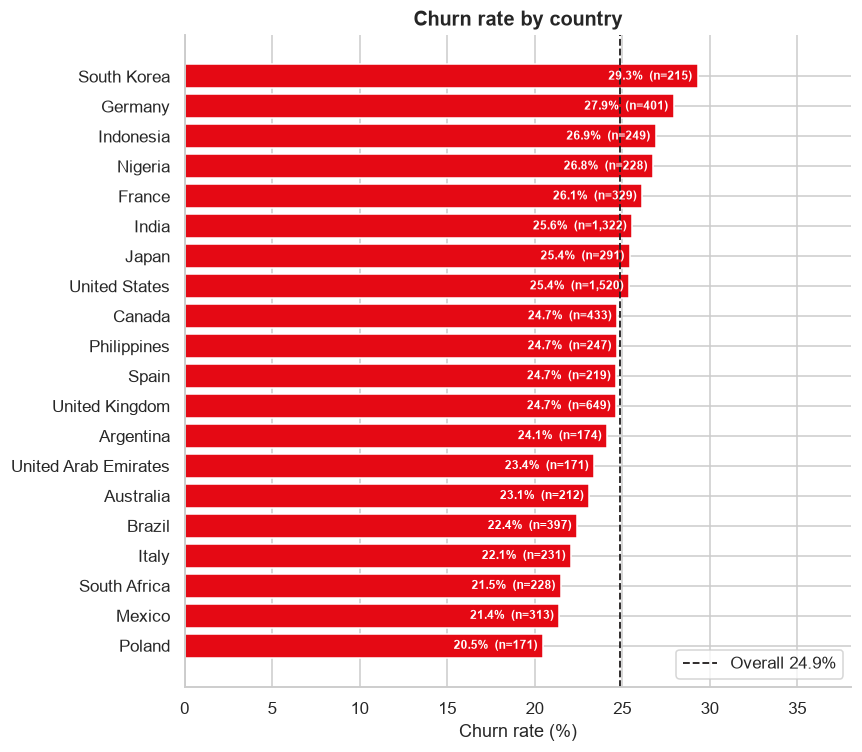

Saved chart 17: reports\figures\eda_17_churn_by_country.png


In [24]:
# Chart 17 — Churn rate by country
_ = churn_rate_chart("country", 17, "churn_by_country", "Churn rate by country", horizontal=True, figsize=(8, 7))

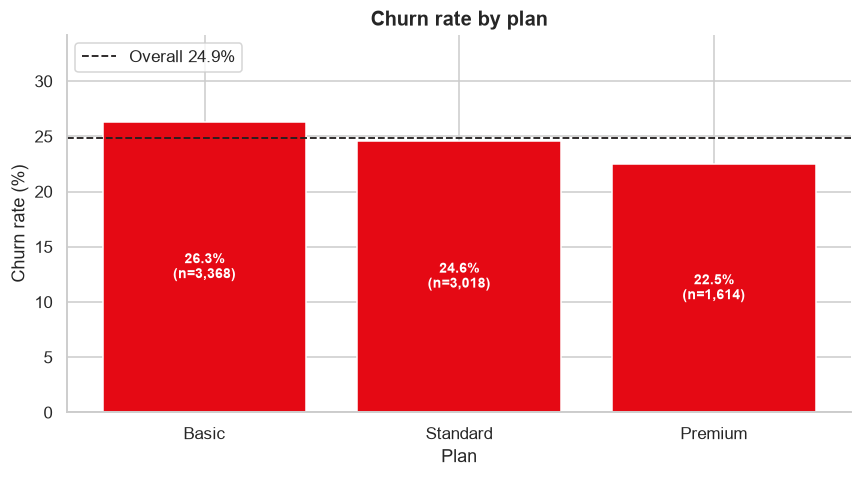

Saved chart 18: reports\figures\eda_18_churn_by_plan.png


In [25]:
# Chart 18 — Churn rate by current plan
_ = churn_rate_chart("plan_name", 18, "churn_by_plan", "Churn rate by plan", order=PLAN_ORDER, xlabel="Plan")

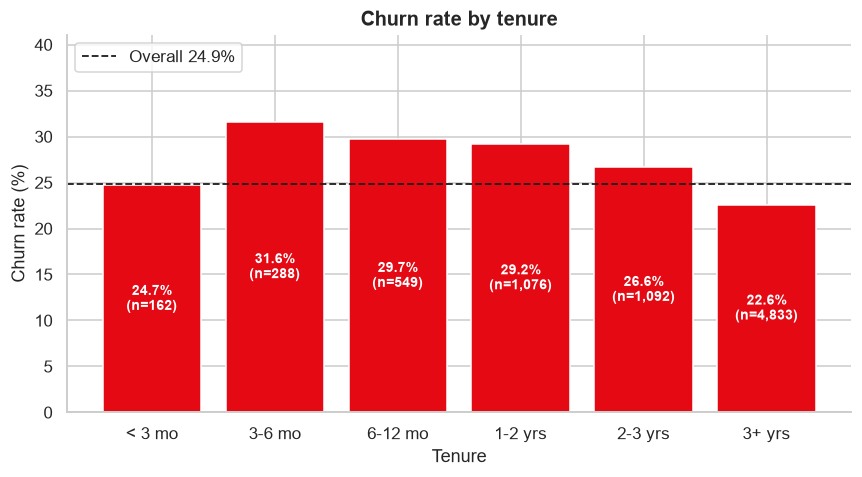

Saved chart 19: reports\figures\eda_19_churn_by_tenure.png


In [26]:
# Chart 19 — Churn rate by tenure (time since registration, measured at the end of the data)
_ = churn_rate_chart("tenure_bucket", 19, "churn_by_tenure", "Churn rate by tenure",
                     order=["< 3 mo", "3-6 mo", "6-12 mo", "1-2 yrs", "2-3 yrs", "3+ yrs"], xlabel="Tenure")

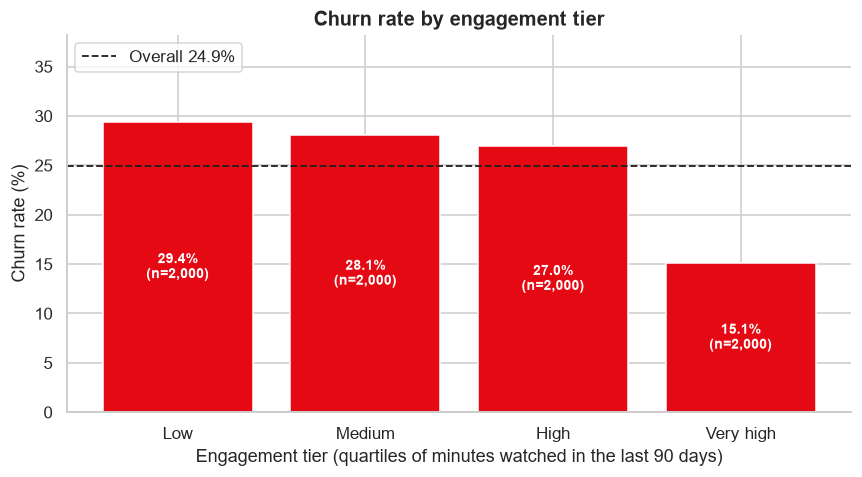

Saved chart 20: reports\figures\eda_20_churn_by_engagement.png


In [27]:
# Chart 20 — Churn rate by engagement tier (minutes watched in the 90 days before cancelling / before the data ends)
_ = churn_rate_chart("engagement_tier", 20, "churn_by_engagement", "Churn rate by engagement tier",
                     order=["Low", "Medium", "High", "Very high"], xlabel="Engagement tier (quartiles of minutes watched in the last 90 days)")

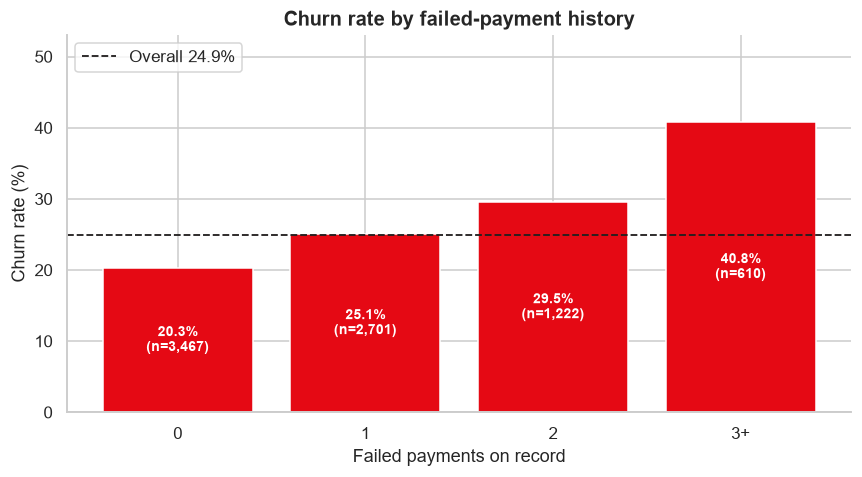

Saved chart 21: reports\figures\eda_21_churn_by_failed_payments.png


In [28]:
# Chart 21 — Churn rate by number of failed payments
_ = churn_rate_chart("failed_bucket", 21, "churn_by_failed_payments", "Churn rate by failed-payment history",
                     order=["0", "1", "2", "3+"], xlabel="Failed payments on record")

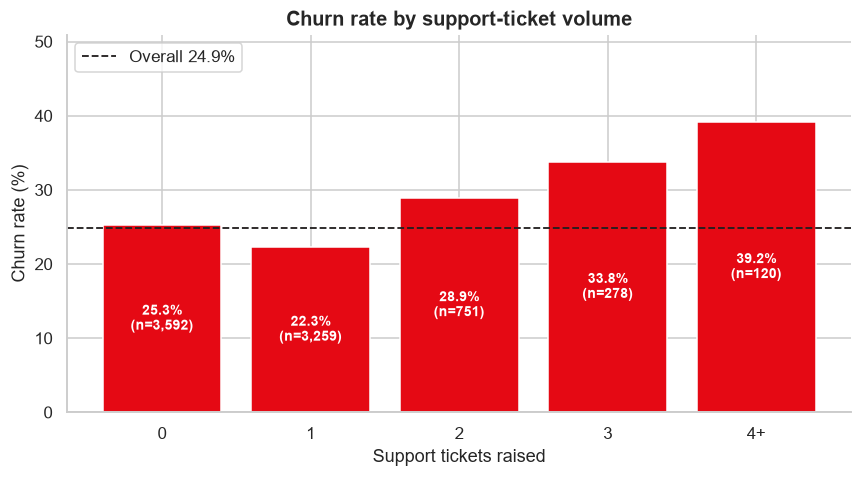

Saved chart 22: reports\figures\eda_22_churn_by_tickets.png


In [29]:
# Chart 22 — Churn rate by number of support tickets
_ = churn_rate_chart("ticket_bucket", 22, "churn_by_tickets", "Churn rate by support-ticket volume",
                     order=["0", "1", "2", "3", "4+"], xlabel="Support tickets raised")

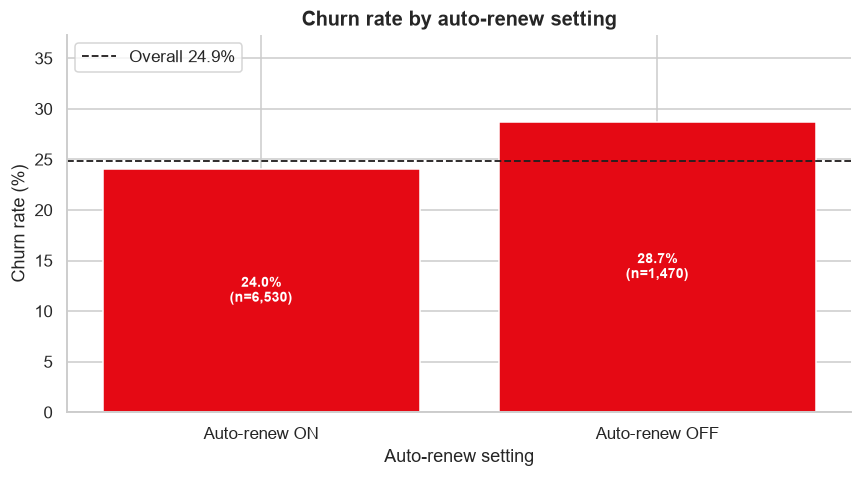

Saved chart 23: reports\figures\eda_23_churn_by_auto_renew.png


In [30]:
# Chart 23 — Churn rate by auto-renew setting
_ = churn_rate_chart("auto_renew_label", 23, "churn_by_auto_renew", "Churn rate by auto-renew setting",
                     order=["Auto-renew ON", "Auto-renew OFF"], xlabel="Auto-renew setting")

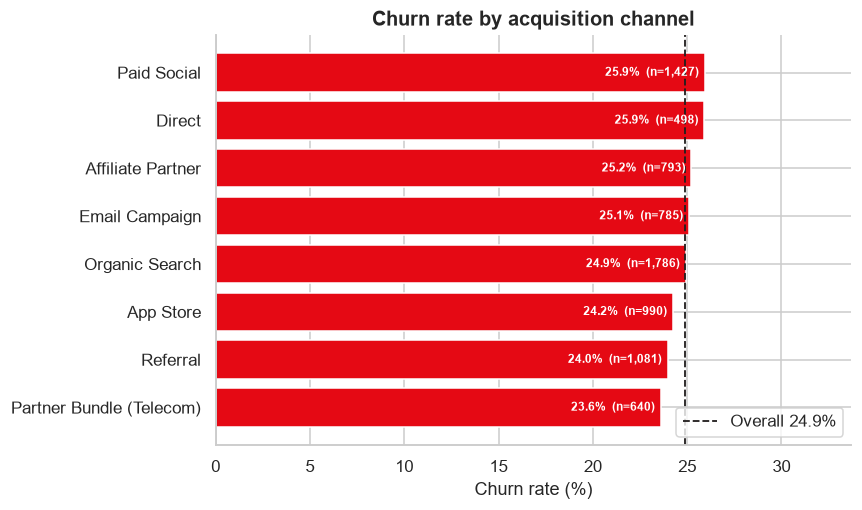

Saved chart 24: reports\figures\eda_24_churn_by_channel.png


In [31]:
# Chart 24 — Churn rate by acquisition channel
_ = churn_rate_chart("acquisition_channel", 24, "churn_by_channel", "Churn rate by acquisition channel",
                     horizontal=True, figsize=(8, 4.8))

**What the charts show** _(associations in a snapshot, not proof of cause)_
- **Failed payments are the clearest warning sign:** churn doubles from 20.3% with no failed payments to 40.8% with three or more.
- **Recent viewing matters:** the most engaged quartile churns at 15.0%, against 27–29% for the other three quartiles.
- **Support contact is a warning sign too:** churn climbs from 22% (one ticket) to 39.2% for customers with four or more tickets.
- **Tenure:** months 3–12 are the riskiest (29.7%–31.6%); customers of 3+ years are the safest (22.6%).
- **Plan and auto-renew:** Basic churns at 26.3%, Standard 24.6%, Premium 22.5%. Customers with auto-renew off churn at 28.7% against 24.0% with it on.
- **Weak drivers:** acquisition channel (23.6%–25.9%) and country (20.5% Poland to 29.3% South Korea, and small countries are noisy).

## 6 · Support

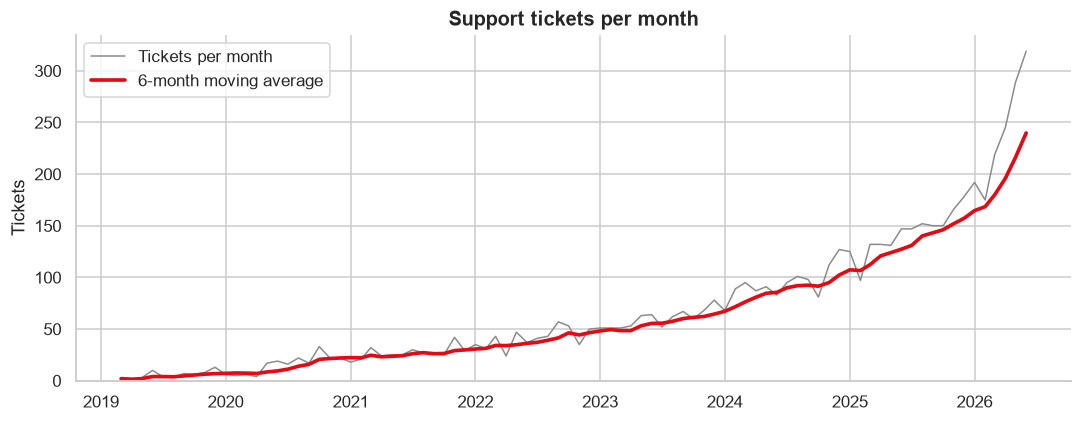

Saved chart 25: reports\figures\eda_25_tickets_per_month.png


In [32]:
# Chart 25 — Support tickets per month
t_ok = tickets.dropna(subset=["ticket_date"])
tpm = t_ok.set_index("ticket_date").resample("MS").size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(tpm.index, tpm.values, color=GREY, lw=1, label="Tickets per month")
ax.plot(tpm.index, tpm.rolling(6, min_periods=1).mean(), color=NETFLIX_RED, lw=2.4, label="6-month moving average")
ax.set_title("Support tickets per month"); ax.set_ylabel("Tickets"); ax.set_ylim(0); ax.legend()
finish(25, "tickets_per_month", fig)

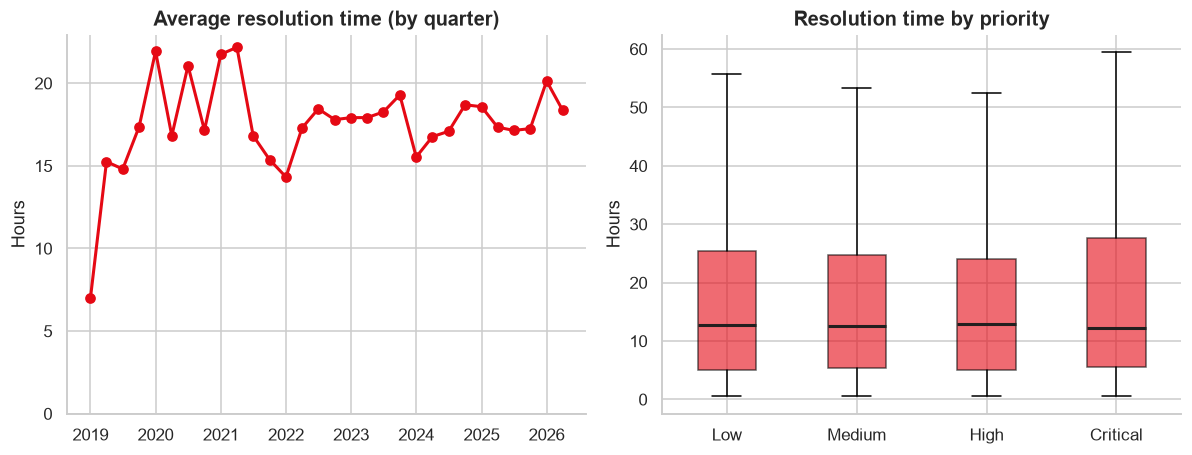

Saved chart 26: reports\figures\eda_26_resolution_time.png


In [33]:
# Chart 26 — Resolution time: monthly trend and spread by priority
res = t_ok.dropna(subset=["resolution_time_hours"])
trend = res.set_index("ticket_date").resample("QS").resolution_time_hours.mean()
prio_order = [p for p in ["Low", "Medium", "High", "Critical"] if p in set(res.priority)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].plot(trend.index, trend.values, color=NETFLIX_RED, marker="o", lw=2)
axes[0].set_title("Average resolution time (by quarter)"); axes[0].set_ylabel("Hours"); axes[0].set_ylim(0)
bp = axes[1].boxplot([res.loc[res.priority == p, "resolution_time_hours"] for p in prio_order], showfliers=False,
                     patch_artist=True, boxprops=dict(facecolor=NETFLIX_RED, alpha=0.6), medianprops=dict(color=DARK, lw=2))
axes[1].set_xticks(range(1, len(prio_order) + 1)); axes[1].set_xticklabels(prio_order)
axes[1].set_title("Resolution time by priority"); axes[1].set_ylabel("Hours")
finish(26, "resolution_time", fig)

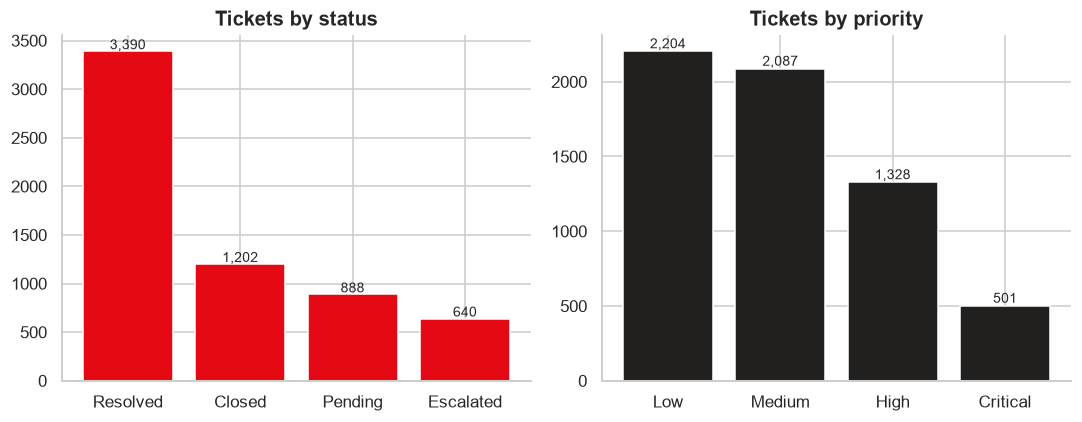

Saved chart 27: reports\figures\eda_27_ticket_status_priority.png


In [34]:
# Chart 27 — Ticket status and priority mix
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
st = tickets.ticket_status.value_counts()
axes[0].bar(st.index, st.values, color=NETFLIX_RED); axes[0].set_title("Tickets by status")
for x, v in enumerate(st.values): axes[0].text(x, v + 20, f"{v:,}", ha="center", fontsize=9)
pr = tickets.priority.value_counts().reindex(["Low", "Medium", "High", "Critical"]).dropna()
axes[1].bar(pr.index, pr.values, color=DARK); axes[1].set_title("Tickets by priority")
for x, v in enumerate(pr.values): axes[1].text(x, v + 20, f"{int(v):,}", ha="center", fontsize=9)
finish(27, "ticket_status_priority", fig)

**What the charts show**
- Ticket volume rises steadily: about 6 a month in 2019, 142 a month in 2025 and 319 in June 2026.
- The average resolution time is 18 hours, and it is the same for every priority (median 12–13 hours even for Critical), so priority does not speed up resolution.
- A quarter of all tickets are still open: 888 Pending and 640 Escalated.

## 7 · Complaints vs. satisfaction (CSAT)

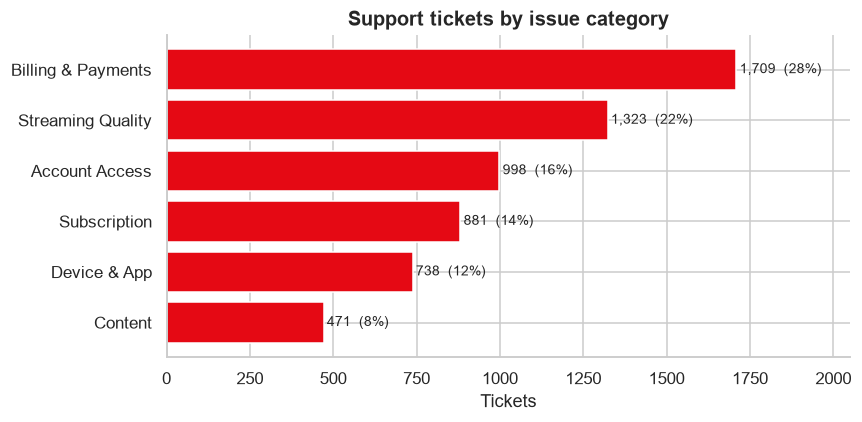

Saved chart 28: reports\figures\eda_28_complaint_categories.png


In [35]:
# Chart 28 — Complaint categories by volume
cat = tickets.issue_category.value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(cat.index[::-1], cat.values[::-1], color=NETFLIX_RED)
for y, v in enumerate(cat.values[::-1]):
    ax.text(v + 10, y, f"{v:,}  ({v / cat.sum():.0%})", va="center", fontsize=9)
ax.set_title("Support tickets by issue category"); ax.set_xlabel("Tickets"); ax.set_xlim(0, cat.max() * 1.2)
finish(28, "complaint_categories", fig)

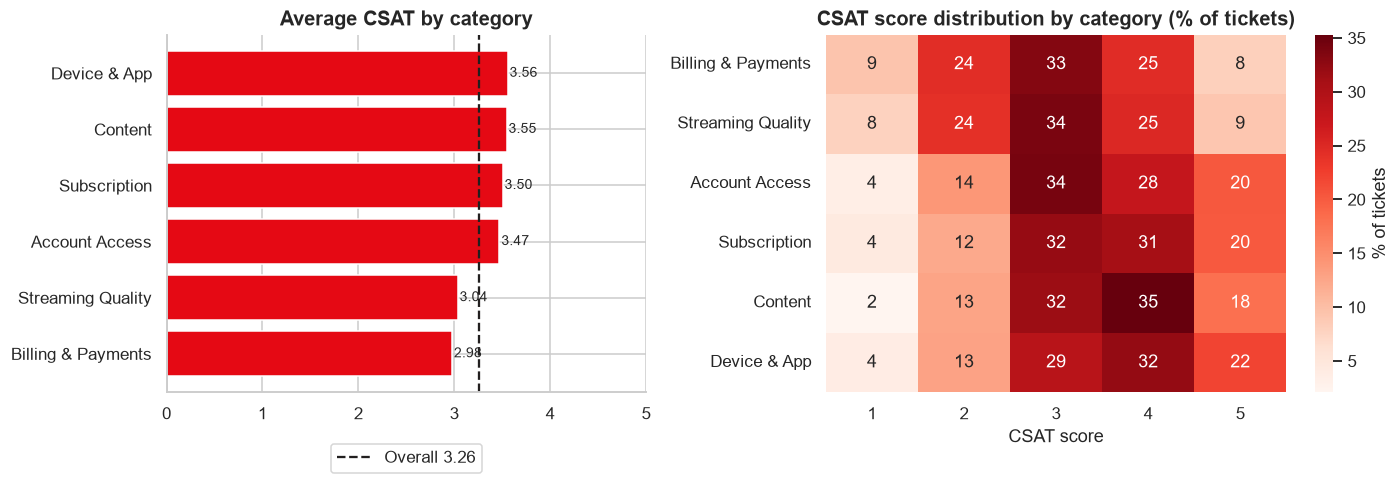

Saved chart 29: reports\figures\eda_29_csat_by_category.png


In [36]:
# Chart 29 — Satisfaction by category: average score and full score distribution
rated = tickets.dropna(subset=["customer_satisfaction_score"]).copy()
rated["csat"] = rated.customer_satisfaction_score.astype(int)
avg_csat = rated.groupby("issue_category").csat.mean().sort_values()
dist = (pd.crosstab(rated.issue_category, rated.csat, normalize="index") * 100).reindex(avg_csat.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].barh(avg_csat.index, avg_csat.values, color=NETFLIX_RED)
for y, v in enumerate(avg_csat.values): axes[0].text(v + 0.02, y, f"{v:.2f}", va="center", fontsize=9)
axes[0].axvline(rated.csat.mean(), color=DARK, ls="--", label=f"Overall {rated.csat.mean():.2f}")
axes[0].set_xlim(0, 5); axes[0].set_title("Average CSAT by category"); axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
sns.heatmap(dist, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% of tickets"}, ax=axes[1])
axes[1].set_title("CSAT score distribution by category (% of tickets)"); axes[1].set_xlabel("CSAT score"); axes[1].set_ylabel("")
finish(29, "csat_by_category", fig)

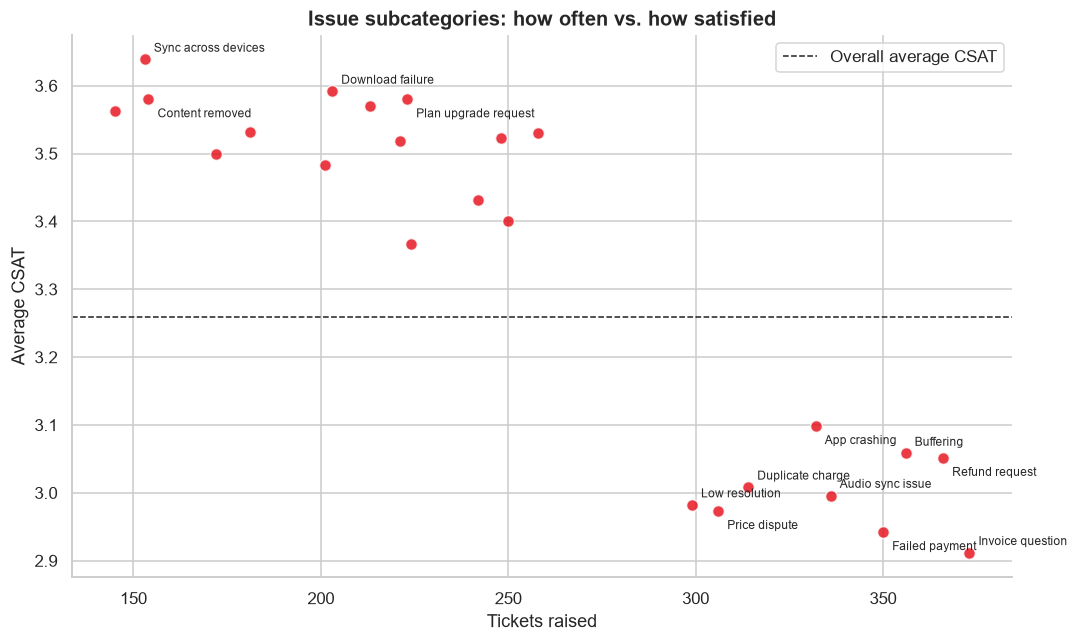

Saved chart 30: reports\figures\eda_30_subcategory_volume_vs_csat.png


In [37]:
# Chart 30 — Complaint volume vs. satisfaction for each issue subcategory
sub = (rated.groupby("issue_subcategory").agg(avg_csat=("csat", "mean"), n=("csat", "size")).reset_index())
vol = tickets.issue_subcategory.value_counts().rename("tickets")
sub = sub.merge(vol, left_on="issue_subcategory", right_index=True)
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sub.tickets, sub.avg_csat, s=60, color=NETFLIX_RED, alpha=0.8, edgecolor="white")
label_idx = set(sub.nlargest(8, "tickets").index) | set(sub.nsmallest(4, "avg_csat").index) | set(sub.nlargest(4, "avg_csat").index)
for k, (i, r) in enumerate(sub.loc[sorted(label_idx)].sort_values("tickets").iterrows()):
    ax.annotate(r.issue_subcategory, (r.tickets, r.avg_csat), xytext=(6, 5 if k % 2 == 0 else -12),
                textcoords="offset points", fontsize=8)
ax.axhline(rated.csat.mean(), color=DARK, ls="--", lw=1, label="Overall average CSAT")
ax.set_title("Issue subcategories: how often vs. how satisfied"); ax.set_xlabel("Tickets raised"); ax.set_ylabel("Average CSAT"); ax.legend()
finish(30, "subcategory_volume_vs_csat", fig)

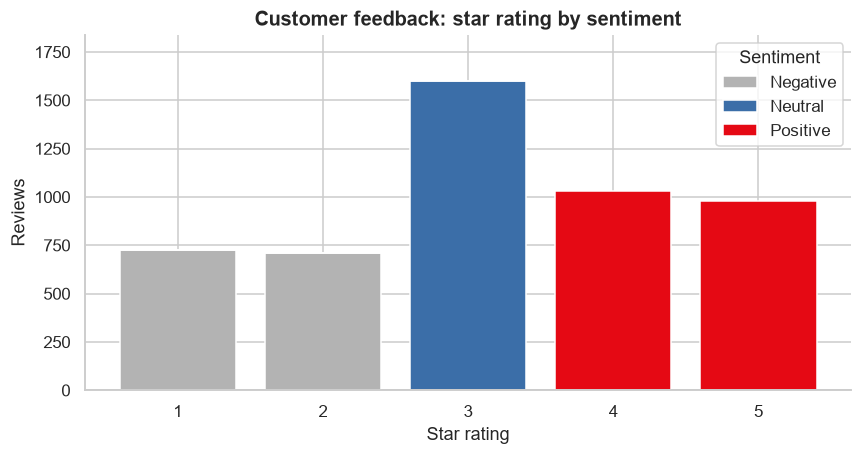

Saved chart 31: reports\figures\eda_31_feedback_ratings.png


In [38]:
# Chart 31 — Feedback ratings by (corrected) sentiment
fb = pd.crosstab(feedback.rating, feedback.sentiment_corrected)
fb = fb.reindex(columns=[c for c in ["Negative", "Neutral", "Positive"] if c in fb.columns])
fig, ax = plt.subplots(figsize=(8, 4.3))
bottom = np.zeros(len(fb))
for c, col in zip(fb.columns, ["#B3B3B3", BLUE, NETFLIX_RED]):
    ax.bar(fb.index.astype(str), fb[c], bottom=bottom, label=c, color=col); bottom = bottom + fb[c].values
ax.set_ylim(0, fb.sum(axis=1).max() * 1.15)
ax.set_title("Customer feedback: star rating by sentiment"); ax.set_xlabel("Star rating"); ax.set_ylabel("Reviews"); ax.legend(title="Sentiment")
finish(31, "feedback_ratings", fig)

**What the charts show**
- Billing & Payments is the biggest category (28% of tickets) and the least satisfying (CSAT 2.98). Streaming Quality is next (22%, CSAT 3.04). The overall average is 3.26.
- The worst subcategories are Invoice question (2.91), Failed payment (2.94), Price dispute (2.97) and Low resolution (2.98). The best are Sync across devices (3.64) and Download failure (3.59).
- Billing problems also show up on the churn side (failed payments, chart 21), which links the support and churn findings.

## 8 · Putting it together

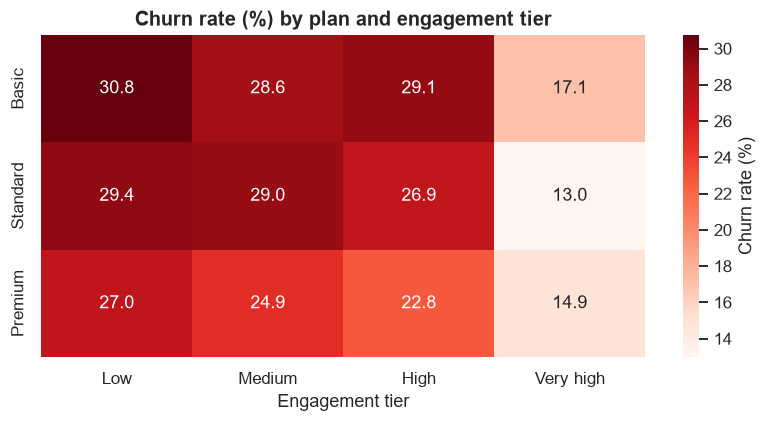

Saved chart 32: reports\figures\eda_32_churn_plan_by_engagement.png


In [39]:
# Chart 32 — Churn rate by plan and engagement tier
hm = (cust.pivot_table(index="plan_name", columns="engagement_tier", values="churned", aggfunc="mean", observed=True)
      .reindex(PLAN_ORDER) * 100)
fig, ax = plt.subplots(figsize=(7.5, 4))
sns.heatmap(hm, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Churn rate (%) by plan and engagement tier"); ax.set_xlabel("Engagement tier"); ax.set_ylabel("")
finish(32, "churn_plan_by_engagement", fig)

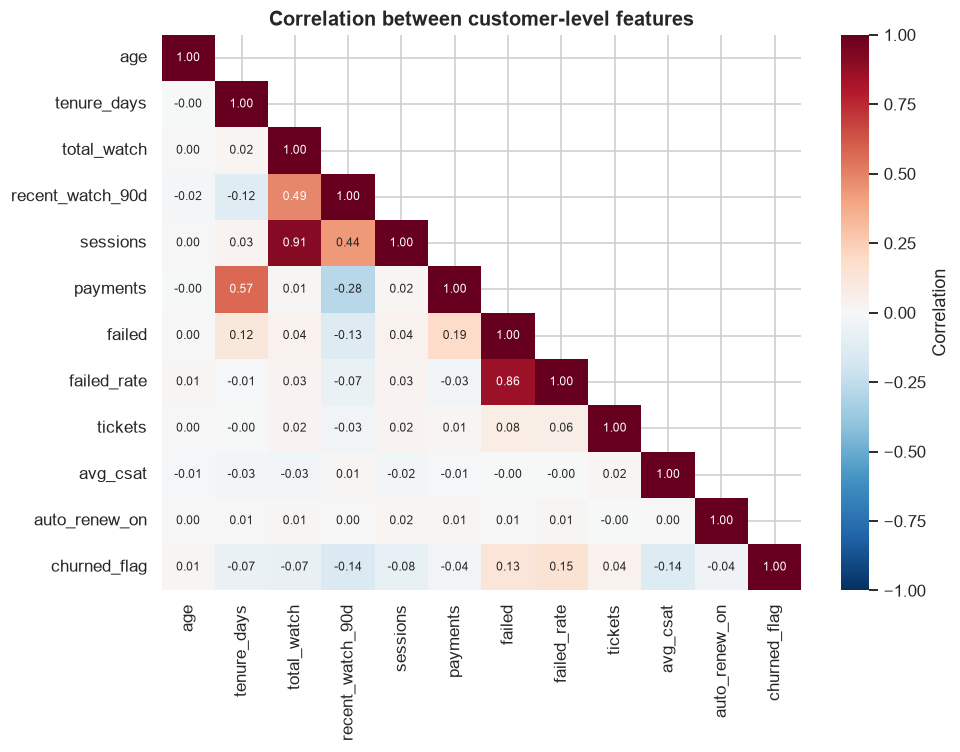

Saved chart 33: reports\figures\eda_33_feature_correlations.png
Correlation with churn:
recent_watch_90d   -0.145
avg_csat           -0.139
sessions           -0.079
total_watch        -0.074
tenure_days        -0.070
auto_renew_on      -0.042
payments           -0.037
age                 0.008
tickets             0.040
failed              0.131
failed_rate         0.147


In [40]:
# Chart 33 — How the customer-level signals move together
feat = cust.assign(auto_renew_on=cust.auto_renew.astype(int), churned_flag=cust.churned.astype(int))
cols = ["age", "tenure_days", "total_watch", "recent_watch_90d", "sessions", "payments", "failed", "failed_rate",
        "tickets", "avg_csat", "auto_renew_on", "churned_flag"]
corr = feat[cols].astype(float).corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            cbar_kws={"label": "Correlation"}, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation between customer-level features")
finish(33, "feature_correlations", fig)
print("Correlation with churn:"); print(corr["churned_flag"].drop("churned_flag").sort_values().round(3).to_string())

**What the charts show**
- The strongest correlations with churn are the failed-payment rate (+0.15), recent watch time (−0.15), average CSAT (−0.14) and the number of failed payments (+0.13). None is above 0.15 in absolute value, so churn is noisy and no single feature predicts it.
- Signals combine: Basic customers with low engagement churn at 30.7%, while Standard customers with very high engagement churn at 13.0%.

**Hand-off to Week 2 (feature engineering and modelling):** build features from failed payments, recent viewing activity, support tickets and satisfaction, tenure, plan and auto-renew, and cut every feature off before the prediction date so the models do not see the future.

## Wrap-up

In [41]:
# Summary of headline numbers and saved charts
active_n = int((cust.subscription_status == "Active").sum())
print(f"Customers: {len(cust):,} | active: {active_n:,} | churned: {int(cust.churned.sum()):,} ({OVERALL:.2%})")
print(f"MRR (active subscribers x plan price): ${mrr.sum():,.2f}")
print(f"Viewing sessions: {len(viewing):,} | payments: {len(payments):,} | tickets: {len(tickets):,}")
figs = sorted(FIG_DIR.glob("eda_*.png"))
print(f"\n{len(figs)} charts saved in {FIG_DIR.relative_to(ROOT)}")

Customers: 8,000 | active: 6,009 | churned: 1,991 (24.89%)
MRR (active subscribers x plan price): $81,364.91
Viewing sessions: 66,422 | payments: 110,735 | tickets: 6,120

33 charts saved in reports\figures
